<a href="https://colab.research.google.com/github/vc-alejandro/CNN-Deep-Learning-Imagewoof/blob/main/imagewoof_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Clasificación de razas de perros con una CNN (Imagewoof)
**Implementación de un modelo de deep learning** (Keras + TensorFlow)

Alejandro Vázquez de la Cruz

In [1]:
import os
import random
import tarfile
import urllib.request
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# Épocas máximas (EarlyStopping corta antes si val_loss deja de mejorar)
EPOCHS_BASE = 25
EPOCHS_REG = 50
EPOCHS_ARCH = 50

# Precisión mixta: acelera el entrenamiento en GPU (T4 de Colab)
USE_MIXED_PRECISION = bool(tf.config.list_physical_devices("GPU"))
if USE_MIXED_PRECISION:
    keras.mixed_precision.set_global_policy("mixed_float16")

sns.set_theme(style="whitegrid")
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"), "| precisión mixta:", USE_MIXED_PRECISION)

TensorFlow: 2.21.0 | Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')] | precisión mixta: True


# 1. Introducción

**Problema.** Clasificar la raza de un perro a partir de una fotografía, entre 10 razas posibles. Se trabaja con *Imagewoof*, un subconjunto de 10 clases de razas de perro, visualmente parecidas entre sí (por ejemplo, varias razas de terrier), de modo que no basta con reconocer "un perro", sino distinguir rasgos finos como el tamaño y la forma de las orejas, la textura y el color del pelaje o la forma del hocico.

**Relevancia.** Es un problema de clasificación *fine-grained* (de grano fino), el mismo tipo de tarea que aparece al identificar especies animales o vegetales, productos casi idénticos o defectos sutiles en piezas. Las redes convolucionales son la herramienta natural porque aprenden de forma jerárquica rasgos locales (bordes, texturas) y los combinan en patrones más complejos.

**Objetivo.** Entrenar una CNN con Keras/TensorFlow **desde cero** (sin usar transfer learning), evaluarla con conjuntos de validación y prueba, y mejorarla con regularización, *data augmentation* y cambios de arquitectura.

# 2. Datos

## 2.1 Descripción y fuente
- **Fuente:** [Imagewoof](https://github.com/fastai/imagenette#imagewoof), Se usa la versión de **320 px** (lado menor de 320 píxeles).
- **Contenido:** 12,954 imágenes a color de 10 razas: Australian terrier, Border terrier, Samoyed, Beagle, Shih-Tzu, English foxhound, Rhodesian ridgeback, Dingo, Golden retriever y Old English sheepdog. Vienen separadas en carpetas `train` (9,025) y `val` (3,929), con una carpeta por clase (identificada con su código de ImageNet).


In [2]:
# [DOWNLOAD]
URL = "https://s3.amazonaws.com/fast-ai-imageclas/imagewoof2-320.tgz"
DATA_DIR = Path("data")
DATA_ROOT = DATA_DIR / "imagewoof2-320"

if not DATA_ROOT.exists():
    DATA_DIR.mkdir(exist_ok=True)
    archive, _ = urllib.request.urlretrieve(URL, DATA_DIR / "imagewoof2-320.tgz")
    with tarfile.open(archive) as tar:
        tar.extractall(DATA_DIR, filter="data")

TRAIN_DIR = DATA_ROOT / "train"
TEST_DIR = DATA_ROOT / "val"   # la carpeta `val` original se usa como conjunto de PRUEBA
print("Ruta:", DATA_ROOT, "| carpetas:", sorted(p.name for p in DATA_ROOT.iterdir() if p.is_dir()))

Ruta: data/imagewoof2-320 | carpetas: ['train', 'val']


In [3]:
# Código de ImageNet -> nombre de la raza
CODE_TO_NAME = {
    "n02086240": "Shih-Tzu",
    "n02087394": "Rhodesian ridgeback",
    "n02088364": "Beagle",
    "n02089973": "English foxhound",
    "n02093754": "Border terrier",
    "n02096294": "Australian terrier",
    "n02099601": "Golden retriever",
    "n02105641": "Old English sheepdog",
    "n02111889": "Samoyed",
    "n02115641": "Dingo",
}

## 2.2 Análisis exploratorio

,train,val (prueba),total
Shih-Tzu,941,409,1350
Rhodesian ridgeback,942,408,1350
Beagle,932,418,1350
English foxhound,580,224,804
Border terrier,949,401,1350
Australian terrier,943,407,1350
Golden retriever,949,401,1350
Old English sheepdog,928,422,1350
Samoyed,921,429,1350
Dingo,940,410,1350


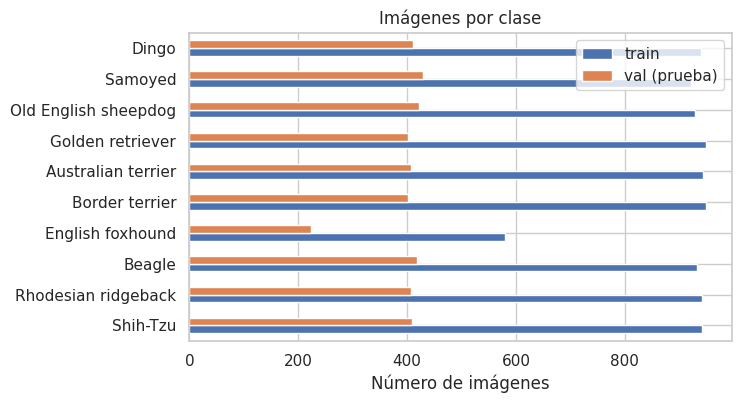

Clase más pequeña: English foxhound (580) | más grande: Border terrier (949) | razón: 0.61


In [4]:
IMG_EXT = {".jpg", ".jpeg", ".png"}


def count_images(split_dir):
    rows = {}
    for c in sorted(p for p in split_dir.iterdir() if p.is_dir()):
        rows[CODE_TO_NAME.get(c.name, c.name)] = sum(f.suffix.lower() in IMG_EXT for f in c.iterdir())
    return pd.Series(rows)


counts = pd.DataFrame({"train": count_images(TRAIN_DIR), "val (prueba)": count_images(TEST_DIR)})
counts["total"] = counts.sum(axis=1)
counts.loc["TOTAL"] = counts.sum()
display(counts)

counts.drop("TOTAL")[["train", "val (prueba)"]].plot(kind="barh", figsize=(7, 4))
plt.title("Imágenes por clase")
plt.xlabel("Número de imágenes")
plt.show()

tr = counts.drop("TOTAL")["train"]
print(f"Clase más pequeña: {tr.idxmin()} ({tr.min()}) | más grande: {tr.idxmax()} ({tr.max()}) | razón: {tr.min() / tr.max():.2f}")

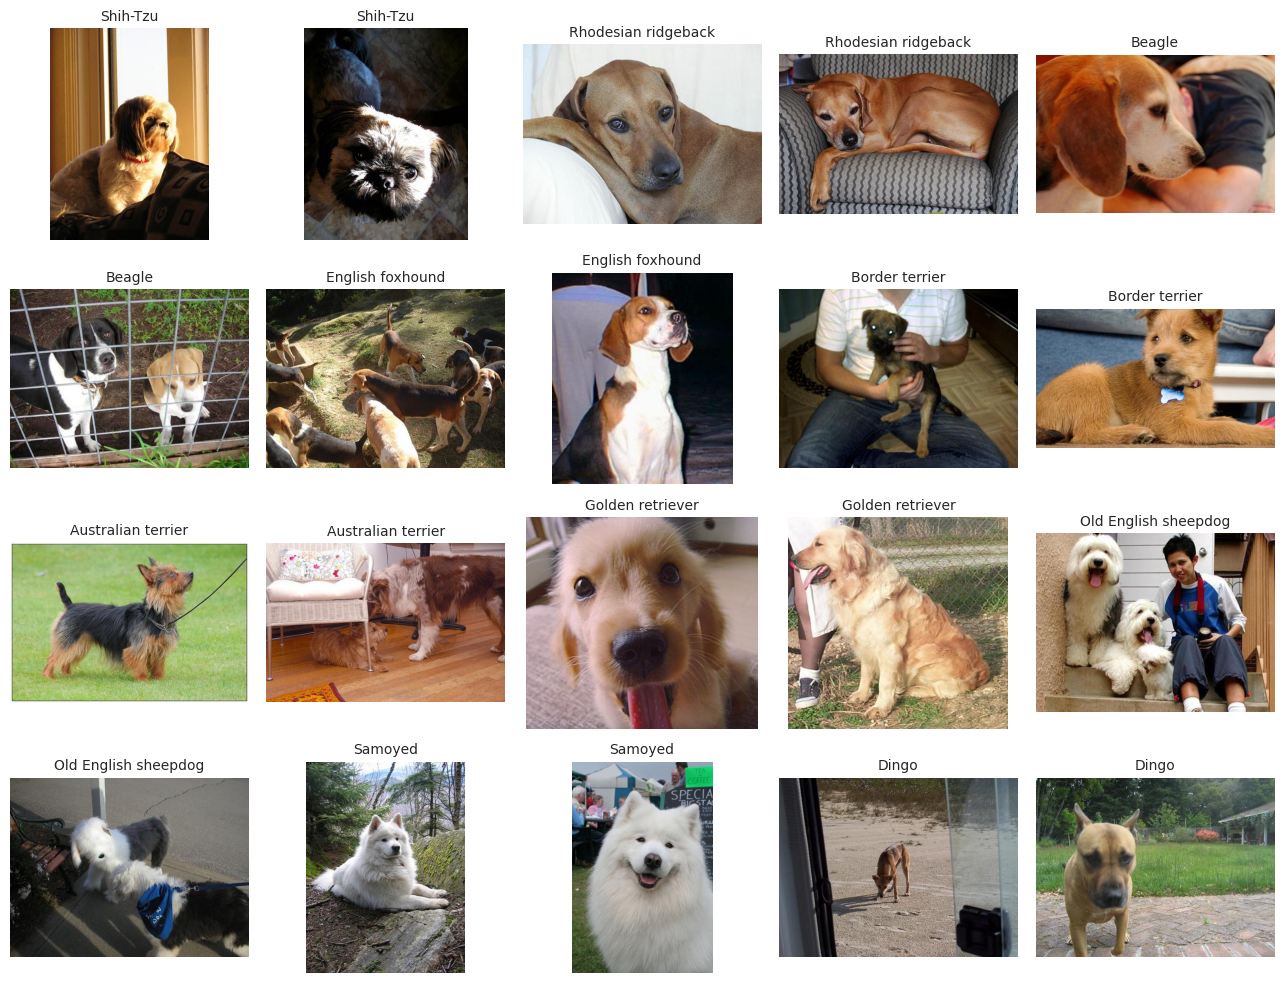

In [5]:
# Ejemplos: 2 imágenes por clase
rng = random.Random(SEED)
codes = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir())
fig, axes = plt.subplots(4, 5, figsize=(13, 10))
for ax, (cls, f) in zip(axes.ravel(), [(c, f) for c in codes for f in rng.sample(sorted((TRAIN_DIR / c).iterdir()), 2)]):
    ax.imshow(Image.open(f).convert("RGB"))
    ax.set_title(CODE_TO_NAME[cls], fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
# Tamaños y modos de color en una muestra aleatoria de train
all_files = [f for f in TRAIN_DIR.rglob("*") if f.suffix.lower() in IMG_EXT]
sample = random.Random(SEED).sample(all_files, k=min(500, len(all_files)))

shapes, modes = [], Counter()
for f in sample:
    with Image.open(f) as im:
        shapes.append(im.size)
        modes[im.mode] += 1

w, h = np.array(shapes).T
print(f"Ancho: min={w.min()}, mediana={int(np.median(w))}, max={w.max()}")
print(f"Alto : min={h.min()}, mediana={int(np.median(h))}, max={h.max()}")
print("Modos de color:", dict(modes))

Ancho: min=320, mediana=426, max=723
Alto : min=320, mediana=320, max=526
Modos de color: {'RGB': 493, 'L': 7}


**Observaciones del análisis (verificar con las salidas de arriba):**
- Hay un **desbalance de clases**: *English foxhound* tiene bastantes menos imágenes que el resto. Por eso, además de *accuracy*, se revisan precisión y recall por clase.
- Las imágenes tienen tamaños y proporciones distintos, así que hay que llevarlas a un tamaño fijo (224×224).
- Algunas imágenes están en escala de grises (modo `L`); se convierten a RGB al cargarlas.
- Las fotos tienen fondos, poses, encuadres e iluminación muy variados: justifica el uso de *data augmentation*.

## 2.3 Separación en entrenamiento, validación y prueba
- **Prueba:** carpeta `val` original de Imagewoof (3,929 imágenes). No se usa para tomar decisiones; se evalúa una sola vez al final con el modelo elegido.
- **Entrenamiento / Validación:** la carpeta `train` se divide 80 % / 20 % con semilla fija. La validación sirve para comparar modelos y detener el entrenamiento.

## 2.4 Preprocesamiento
- Redimensionado a 224×224 con recorte centrado (conserva la proporción, equivalente a *Resize + CenterCrop*).
- Conversión a RGB.
- El reescalado de píxeles a [0, 1] se hace **dentro del modelo** (capa `Rescaling`)

In [7]:
common = dict(
    image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode="categorical",
    color_mode="rgb", crop_to_aspect_ratio=True,
)

train_ds, val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, validation_split=0.2, subset="both", seed=SEED, **common
)
test_ds = keras.utils.image_dataset_from_directory(TEST_DIR, shuffle=False, **common)

class_names = train_ds.class_names                       # códigos de ImageNet, en orden alfabético
assert class_names == test_ds.class_names
NUM_CLASSES = len(class_names)
breed_names = [CODE_TO_NAME[c] for c in class_names]     # nombres legibles
print("Clases:", breed_names)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 9025 files belonging to 10 classes.
Using 7220 files for training.
Using 1805 files for validation.
Found 3929 files belonging to 10 classes.
Clases: ['Shih-Tzu', 'Rhodesian ridgeback', 'Beagle', 'English foxhound', 'Border terrier', 'Australian terrier', 'Golden retriever', 'Old English sheepdog', 'Samoyed', 'Dingo']


# 3. Desarrollo del modelo

## 3.1 Funciones auxiliares

In [9]:
results = {}   # métricas de validación por modelo
models = {}    # modelos entrenados
histories = {}


def plot_history(hist, title=""):
    h = hist.history if hasattr(hist, "history") else hist
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h["loss"], label="train")
    ax[0].plot(h["val_loss"], label="val")
    ax[0].set(title=f"{title} · Loss", xlabel="Época", ylabel="Loss")
    ax[1].plot(h["accuracy"], label="train")
    ax[1].plot(h["val_accuracy"], label="val")
    ax[1].set(title=f"{title} · Accuracy", xlabel="Época", ylabel="Accuracy")
    for a in ax:
        a.legend()
    plt.tight_layout()
    plt.show()


def predict_split(model, ds):
    """Devuelve (y_true, y_pred, probabilidades) respetando el orden del dataset."""
    y_true, y_prob = [], []
    for x, y in ds:
        y_prob.append(model.predict_on_batch(x))
        y_true.append(np.argmax(y.numpy(), axis=1))
    y_prob = np.concatenate(y_prob)
    return np.concatenate(y_true), y_prob.argmax(axis=1), y_prob


def plot_confusion(y_true, y_pred, title=""):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6.5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=breed_names, yticklabels=breed_names)
    plt.xlabel("Predicción")
    plt.ylabel("Valor real")
    plt.title(title)
    plt.xticks(rotation=60, ha="right")
    plt.show()


def make_callbacks(patience, reduce_lr=False):
    cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True)]
    if reduce_lr:
        cbs.append(keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6))
    return cbs


def register(name, model, hist):
    """Evalúa en validación y guarda el modelo para compararlo después."""
    val_loss, val_acc = model.evaluate(val_ds, verbose=0)
    results[name] = {"val_loss": val_loss, "val_acc": val_acc, "parámetros": model.count_params()}
    models[name] = model
    histories[name] = hist
    print(f"{name}: val_loss={val_loss:.4f} | val_acc={val_acc:.4f}")

## 3.2 Arquitectura base
CNN de 5 bloques `Conv2D(3×3) → BatchNorm → ReLU → MaxPool(2)` con filtros **64 → 128 → 256 → 128 → 64**, seguida de `GlobalAveragePooling2D` y una cabeza densa (256 neuronas, ReLU) con salida *softmax* de 10 clases.

Esta primera versión **no** incluye regularización ni *data augmentation*, para poder medir después el efecto de cada mejora

In [8]:
def build_cnn(filters=(64, 128, 256, 128, 64), convs_per_block=1, dropouts=(0, 0, 0, 0, 0),
              dense_units=256, head_dropout=0.0, augmentation=None, name="cnn"):
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = augmentation(inputs) if augmentation is not None else inputs
    x = layers.Rescaling(1.0 / 255)(x)
    for f, d in zip(filters, dropouts):
        for _ in range(convs_per_block):
            x = layers.Conv2D(f, 3, padding="same", use_bias=False)(x)
            x = layers.BatchNormalization()(x)
            x = layers.ReLU()(x)
        x = layers.MaxPooling2D(2)(x)
        if d:
            x = layers.Dropout(d)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation="relu")(x)
    if head_dropout:
        x = layers.Dropout(head_dropout)(x)
    outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32")(x)   # float32 por precisión mixta
    return keras.Model(inputs, outputs, name=name)


cnn_base = build_cnn(name="cnn_base")
cnn_base.compile(optimizer=keras.optimizers.Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
cnn_base.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 64)   │         1,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 224, 224, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 128)  │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 128)  │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 112, 112, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 14, 14, 64)     │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 760,778 (2.90 MB)

 Trainable params: 759,498 (2.90 MB)

 Non-trainable params: 1,280 (5.00 KB)

## 3.3 Entrenamiento y evaluación inicial (validación)

Epoch 1/25
226/226 - 62s - 273ms/step - accuracy: 0.2289 - loss: 2.0901 - val_accuracy: 0.0903 - val_loss: 3.5726
Epoch 2/25
226/226 - 17s - 75ms/step - accuracy: 0.3363 - loss: 1.8292 - val_accuracy: 0.1535 - val_loss: 4.5165
Epoch 3/25
226/226 - 17s - 73ms/step - accuracy: 0.3986 - loss: 1.6739 - val_accuracy: 0.3357 - val_loss: 1.8977
Epoch 4/25
226/226 - 21s - 91ms/step - accuracy: 0.4463 - loss: 1.5610 - val_accuracy: 0.2371 - val_loss: 2.1762
Epoch 5/25
226/226 - 17s - 76ms/step - accuracy: 0.4733 - loss: 1.4872 - val_accuracy: 0.2803 - val_loss: 2.0295
Epoch 6/25
226/226 - 20s - 88ms/step - accuracy: 0.4965 - loss: 1.4085 - val_accuracy: 0.3618 - val_loss: 1.8914
Epoch 7/25
226/226 - 17s - 74ms/step - accuracy: 0.5360 - loss: 1.3253 - val_accuracy: 0.3939 - val_loss: 1.8351
Epoch 8/25
226/226 - 17s - 76ms/step - accuracy: 0.5554 - loss: 1.2558 - val_accuracy: 0.3363 - val_loss: 1.9693
Epoch 9/25
226/226 - 17s - 75ms/step - accuracy: 0.5986 - loss: 1.1510 - val_accuracy: 0.4593 -

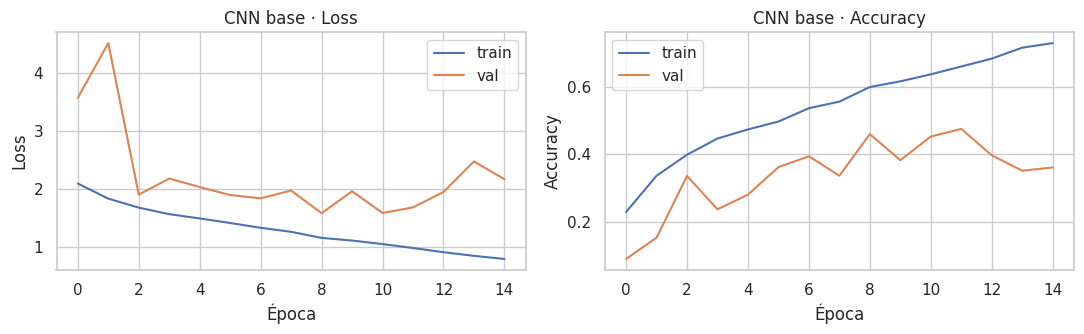

In [10]:
# shuffle=False: image_dataset_from_directory ya mezcla el set de entrenamiento en cada época
hist_base = cnn_base.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_BASE,
    callbacks=make_callbacks(patience=6), shuffle=False, verbose=2,
)
register("1. CNN base", cnn_base, hist_base.history)
plot_history(hist_base, "CNN base")

                      precision    recall  f1-score   support

            Shih-Tzu      0.812     0.068     0.126       190
 Rhodesian ridgeback      0.445     0.783     0.567       175
              Beagle      0.486     0.382     0.428       186
    English foxhound      0.846     0.092     0.165       120
      Border terrier      0.692     0.426     0.527       195
  Australian terrier      0.473     0.508     0.490       187
    Golden retriever      0.353     0.663     0.461       187
Old English sheepdog      0.435     0.568     0.493       183
             Samoyed      0.452     0.840     0.587       194
               Dingo      0.560     0.149     0.235       188

            accuracy                          0.459      1805
           macro avg      0.555     0.448     0.408      1805
        weighted avg      0.546     0.459     0.416      1805



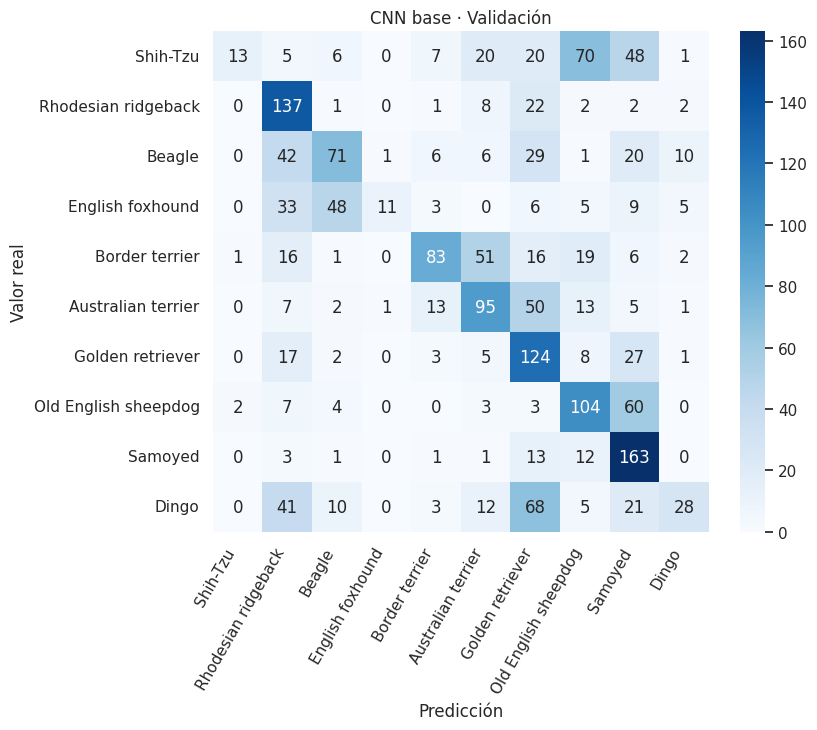

In [11]:
y_val, p_val, _ = predict_split(cnn_base, val_ds)
print(classification_report(y_val, p_val, target_names=breed_names, digits=3, zero_division=0))
plot_confusion(y_val, p_val, "CNN base · Validación")

**Análisis del modelo base (completar con tus resultados):**
- ¿La brecha entre *train* y *val* en las curvas indica sobreajuste? ¿Desde qué época?
- ¿Qué razas se confunden más en la matriz de confusión? ¿Tiene que ver con que sean visualmente parecidas?
- ¿Cómo le va a la clase minoritaria (*English foxhound*)?
- Con esto se definen las mejoras de la sección 4.

# 4. Ajuste del modelo

Se prueban dos iteraciones sobre el modelo base. Todas se comparan en **validación**.

| Iteración | Cambio | Problema que ataca |
|---|---|---|
| 1 | *Data augmentation* + Dropout + *label smoothing* + `ReduceLROnPlateau` | Sobreajuste |
| 2 | Cambio de arquitectura: dos convoluciones por bloque (estilo VGG) con filtros 32 → 64 → 128 → 256 → 256, manteniendo la regularización | Capacidad de la red para distinguir rasgos finos |

## 4.1 Iteración 1: regularización y augmentation
Las transformaciones de *augmentation* son geométricas y de iluminación suaves (volteo horizontal, rotación de hasta ±10°, zoom hacia adentro de hasta 20 %, brillo y contraste ±20 %), que reproducen variaciones naturales en fotos de perros. Solo se aplican durante el entrenamiento.

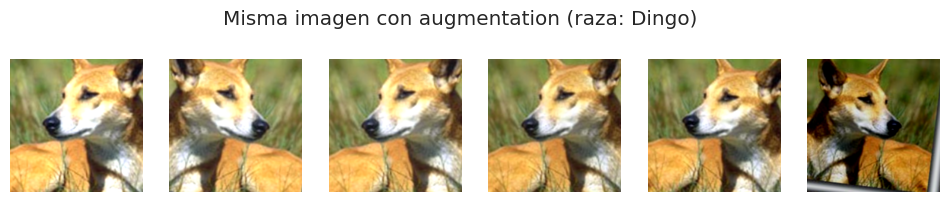

In [12]:
augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(10 / 360),
    layers.RandomZoom(height_factor=(-0.2, 0.0)),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
    layers.RandomContrast(0.2),
], name="augmentation")

# Vista previa de augmentation sobre una imagen de entrenamiento
x_batch, y_batch = next(iter(train_ds))
plt.figure(figsize=(12, 2.4))
for i in range(6):
    plt.subplot(1, 6, i + 1)
    aug = augmentation(x_batch[:1], training=True)
    plt.imshow(np.clip(aug[0].numpy(), 0, 255).astype("uint8"))
    plt.axis("off")
plt.suptitle("Misma imagen con augmentation (raza: %s)" % breed_names[int(np.argmax(y_batch[0]))])
plt.show()

Epoch 1/50
226/226 - 65s - 289ms/step - accuracy: 0.1758 - loss: 2.2280 - val_accuracy: 0.1147 - val_loss: 2.6314 - learning_rate: 0.0010
Epoch 2/50
226/226 - 53s - 236ms/step - accuracy: 0.2183 - loss: 2.1568 - val_accuracy: 0.2249 - val_loss: 2.1425 - learning_rate: 0.0010
Epoch 3/50
226/226 - 53s - 236ms/step - accuracy: 0.2569 - loss: 2.0662 - val_accuracy: 0.2000 - val_loss: 2.4749 - learning_rate: 0.0010
Epoch 4/50
226/226 - 54s - 238ms/step - accuracy: 0.3094 - loss: 1.9736 - val_accuracy: 0.1302 - val_loss: 2.5022 - learning_rate: 0.0010
Epoch 5/50
226/226 - 56s - 249ms/step - accuracy: 0.3410 - loss: 1.9044 - val_accuracy: 0.2853 - val_loss: 2.0024 - learning_rate: 0.0010
Epoch 6/50
226/226 - 54s - 237ms/step - accuracy: 0.3711 - loss: 1.8561 - val_accuracy: 0.2355 - val_loss: 2.3172 - learning_rate: 0.0010
Epoch 7/50
226/226 - 53s - 237ms/step - accuracy: 0.3920 - loss: 1.8102 - val_accuracy: 0.3086 - val_loss: 1.9494 - learning_rate: 0.0010
Epoch 8/50
226/226 - 53s - 237ms/s

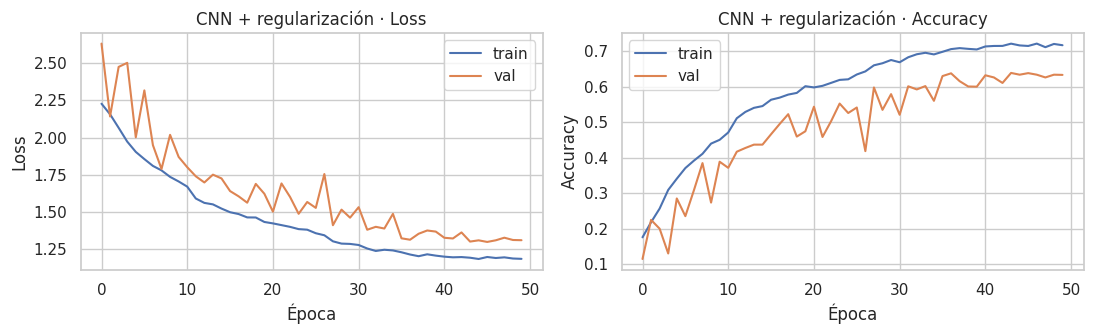

In [13]:
cnn_reg = build_cnn(
    dropouts=(0, 0, 0.3, 0.2, 0.1), head_dropout=0.5,
    augmentation=augmentation, name="cnn_reg",
)
cnn_reg.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"],
)

hist_reg = cnn_reg.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_REG,
    callbacks=make_callbacks(patience=10, reduce_lr=True), shuffle=False, verbose=2,
)
register("2. CNN + regularización", cnn_reg, hist_reg.history)
plot_history(hist_reg, "CNN + regularización")

## 4.2 Iteración 2: cambio de arquitectura
Se añade profundidad dentro de cada bloque (dos convoluciones antes de cada *pooling*), lo que da campos receptivos más grandes y más no linealidad con pocos parámetros extra. Los filtros crecen de forma monótona (32 → 64 → 128 → 256 → 256) en lugar de volver a reducirse como en la base. Se conservan *augmentation*, Dropout y *label smoothing*.

Epoch 1/50
226/226 - 61s - 270ms/step - accuracy: 0.1666 - loss: 2.2567 - val_accuracy: 0.1335 - val_loss: 2.4554 - learning_rate: 0.0010
Epoch 2/50
226/226 - 49s - 216ms/step - accuracy: 0.1911 - loss: 2.1791 - val_accuracy: 0.1446 - val_loss: 2.3052 - learning_rate: 0.0010
Epoch 3/50
226/226 - 49s - 215ms/step - accuracy: 0.2150 - loss: 2.1391 - val_accuracy: 0.1363 - val_loss: 2.6029 - learning_rate: 0.0010
Epoch 4/50
226/226 - 49s - 217ms/step - accuracy: 0.2389 - loss: 2.0865 - val_accuracy: 0.1679 - val_loss: 2.6839 - learning_rate: 0.0010
Epoch 5/50
226/226 - 50s - 220ms/step - accuracy: 0.2719 - loss: 2.0244 - val_accuracy: 0.1407 - val_loss: 2.3123 - learning_rate: 0.0010
Epoch 6/50
226/226 - 49s - 217ms/step - accuracy: 0.3269 - loss: 1.9305 - val_accuracy: 0.2992 - val_loss: 2.0001 - learning_rate: 5.0000e-04
Epoch 7/50
226/226 - 49s - 217ms/step - accuracy: 0.3632 - loss: 1.8721 - val_accuracy: 0.2044 - val_loss: 2.1278 - learning_rate: 5.0000e-04
Epoch 8/50
226/226 - 82s -

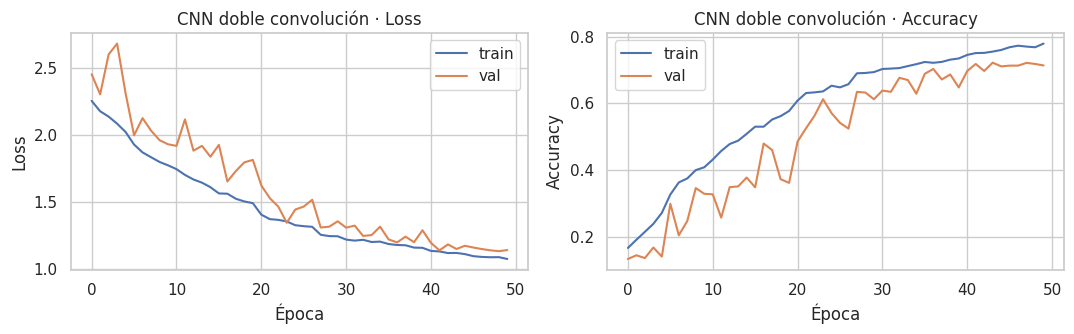

In [14]:
cnn_arch = build_cnn(
    filters=(32, 64, 128, 256, 256), convs_per_block=2,
    dropouts=(0, 0.1, 0.2, 0.3, 0.3), head_dropout=0.5,
    augmentation=augmentation, name="cnn_arch",
)
cnn_arch.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"],
)

hist_arch = cnn_arch.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS_ARCH,
    callbacks=make_callbacks(patience=10, reduce_lr=True), shuffle=False, verbose=2,
)
register("3. CNN doble convolución", cnn_arch, hist_arch.history)
plot_history(hist_arch, "CNN doble convolución")

## 4.3 Comparación en validación

,val_loss,val_acc,parámetros
1. CNN base,1.5777,0.4593,"760,778"
2. CNN + regularización,1.2999,0.6388,"760,778"
3. CNN doble convolución,1.1352,0.7186,"2,425,194"


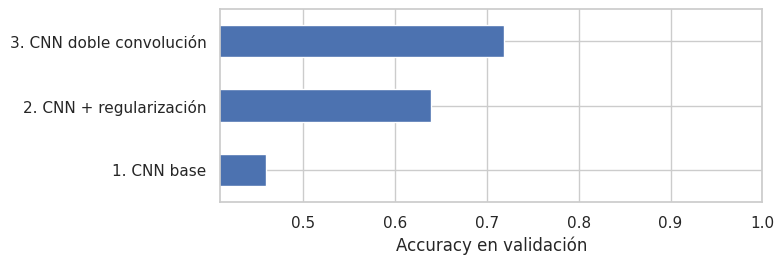

In [15]:
comparison = pd.DataFrame(results).T
comparison["parámetros"] = comparison["parámetros"].astype(int)
display(comparison.style.format({"val_loss": "{:.4f}", "val_acc": "{:.4f}", "parámetros": "{:,}"}))

comparison["val_acc"].plot(kind="barh", figsize=(7, 2.5), xlim=(max(0, comparison["val_acc"].min() - 0.05), 1.0))
plt.xlabel("Accuracy en validación")
plt.show()

## 4.4 Qué funcionó y por qué (completar con tus resultados)

| Cambio | Efecto observado | Por qué funcionó (o no) |
|---|---|---|
| *Data augmentation* | | Genera variaciones de la misma foto (volteo, rotación, zoom, brillo, contraste) y obliga a la red a aprender rasgos de la raza y no a memorizar fondos o encuadres. |
| Dropout | | Evita que la red dependa de neuronas individuales; reduce la brecha *train–val*. |
| *Label smoothing* | | Evita predicciones excesivamente confiadas en clases visualmente parecidas y suaviza la pérdida. |
| `ReduceLROnPlateau` | | Baja la tasa de aprendizaje cuando `val_loss` se estanca, permitiendo un ajuste más fino al final. |
| Doble convolución por bloque | | Mayor capacidad y campo receptivo para distinguir rasgos finos entre razas similares. |

# 5. Resultados

Se elige el modelo con mejor *accuracy* en **validación** y se evalúa **una sola vez** con el conjunto de prueba, que no se usó para ninguna decisión.

Modelo final: 3. CNN doble convolución
Prueba -> loss: 1.1445 | accuracy: 0.7272

                      precision    recall  f1-score   support

            Shih-Tzu      0.742     0.655     0.696       409
 Rhodesian ridgeback      0.837     0.804     0.820       408
              Beagle      0.634     0.770     0.695       418
    English foxhound      0.853     0.286     0.428       224
      Border terrier      0.569     0.823     0.673       401
  Australian terrier      0.834     0.592     0.693       407
    Golden retriever      0.833     0.658     0.735       401
Old English sheepdog      0.758     0.787     0.772       422
             Samoyed      0.845     0.890     0.867       429
               Dingo      0.631     0.795     0.703       410

            accuracy                          0.727      3929
           macro avg      0.754     0.706     0.708      3929
        weighted avg      0.749     0.727     0.722      3929



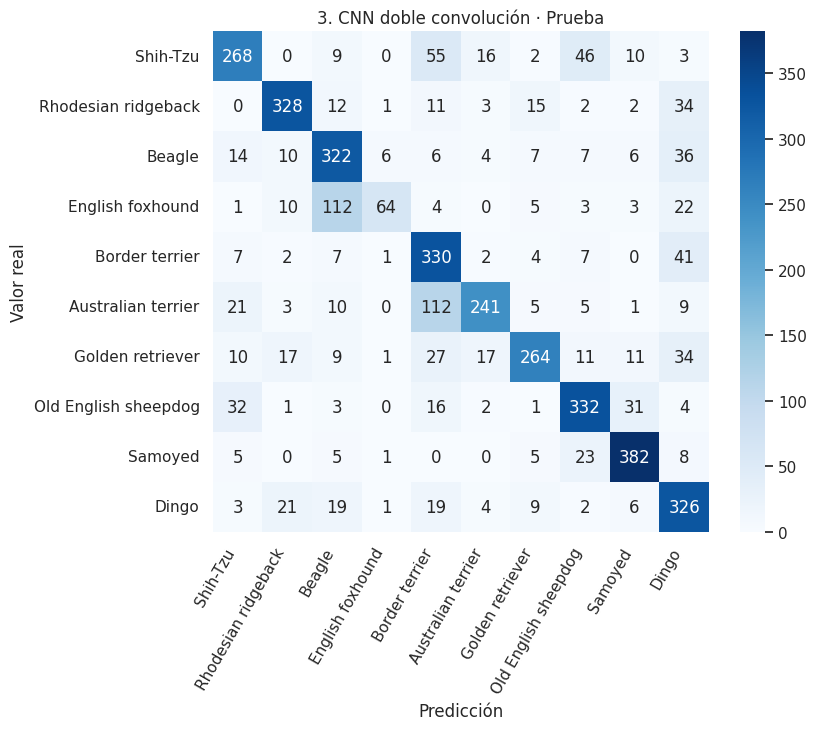

In [16]:
best_name = max(results, key=lambda k: results[k]["val_acc"])
best_model = models[best_name]
print("Modelo final:", best_name)

test_loss, test_acc = best_model.evaluate(test_ds, verbose=0)
print(f"Prueba -> loss: {test_loss:.4f} | accuracy: {test_acc:.4f}")

y_test, p_test, prob_test = predict_split(best_model, test_ds)
print()
print(classification_report(y_test, p_test, target_names=breed_names, digits=3, zero_division=0))
plot_confusion(y_test, p_test, f"{best_name} · Prueba")

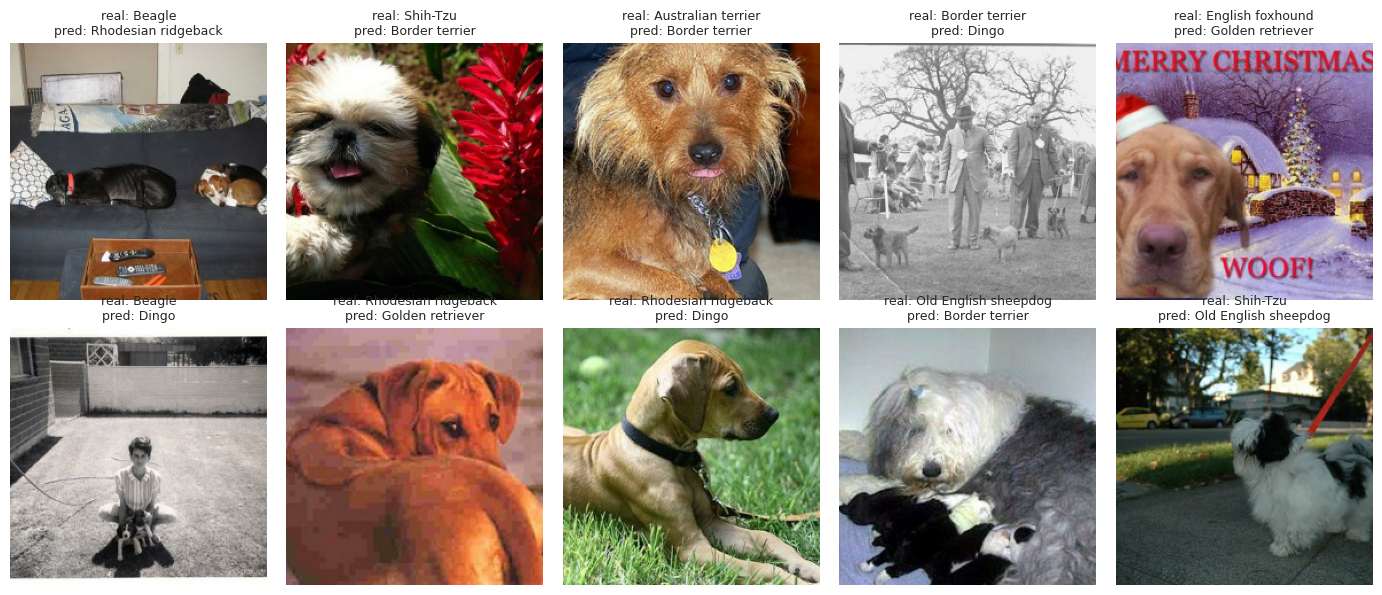

In [17]:
# Ejemplos mal clasificados en prueba (muestra aleatoria de todos los errores)
errors = []
for x, y in test_ds:
    pred = best_model.predict_on_batch(x).argmax(axis=1)
    true = y.numpy().argmax(axis=1)
    for i in np.where(pred != true)[0]:
        errors.append((x[i].numpy().astype("uint8"), true[i], pred[i]))

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, (img, t, p) in zip(axes.ravel(), random.Random(SEED).sample(errors, 10)):
    ax.imshow(img)
    ax.set_title(f"real: {breed_names[t]}\npred: {breed_names[p]}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [18]:
# Guardar el modelo final (arquitectura + pesos) y verificar que se recarga igual
Path("models").mkdir(exist_ok=True)
MODEL_PATH = "models/imagewoof_cnn.keras"
best_model.save(MODEL_PATH)
print(f"Guardado en {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")

reloaded = keras.models.load_model(MODEL_PATH)
x_chk, _ = next(iter(test_ds))
print("Predicciones idénticas tras recargar:",
      np.allclose(best_model.predict(x_chk, verbose=0), reloaded.predict(x_chk, verbose=0), atol=1e-3))

Guardado en models/imagewoof_cnn.keras (48.7 MB)
Predicciones idénticas tras recargar: True


# 6. Conclusiones

**Resultados (completar):**
- Modelo final y métricas en prueba: *accuracy* = …, raza con mejor y peor recall = …
- Mejora respecto al modelo base y qué cambio aportó más: …
- Razas más confundidas y posible explicación (similitud visual, desbalance): …

**Limitaciones**
- La red se entrena desde cero con ~7,200 imágenes de entrenamiento; con tan pocos datos, la capacidad de generalizar en una tarea de grano fino es limitada.
- El desbalance de *English foxhound* (menos imágenes) afecta su recall.
- Las imágenes provienen de ImageNet: fondos, poses y estilo fotográfico siguen ese sesgo, y el conjunto de prueba sale de la misma distribución, por lo que no mide generalización a fotos totalmente distintas.
- Por costo de cómputo se probaron pocas configuraciones, sin búsqueda sistemática de hiperparámetros.

**Áreas de mejora**
- Compensar el desbalance con pesos por clase (`class_weight`) o *oversampling*.
- Técnicas de augmentation más fuertes (*Mixup*, *CutMix*) y entrenamiento más largo con un *scheduler* (por ejemplo, *cosine decay*).
- Búsqueda de hiperparámetros con KerasTuner (tasa de aprendizaje, dropout, anchura de la red).
- Conexiones residuales para entrenar redes más profundas, o transfer learning como comparación.
- Interpretabilidad con Grad-CAM para verificar en qué zona de la imagen se apoya el modelo.

# 7. Aplicación

Función que recibe la ruta de una imagen y devuelve la raza predicha con su probabilidad. Se carga el modelo desde el archivo `.keras` para demostrar que funciona de forma independiente al entrenamiento.

In [19]:
modelo = keras.models.load_model("models/imagewoof_cnn.keras")


def predict_image(path, model=modelo, top_k=3, show=True):
    """Clasifica la raza de un perro. Entrada: ruta a una imagen. Salida: (raza, probabilidad)."""
    img = keras.utils.load_img(path, color_mode="rgb")
    arr = keras.utils.img_to_array(img)
    # Mismo preprocesamiento que en entrenamiento: recorte centrado a la proporción 1:1 y resize a 224x224
    side = min(arr.shape[0], arr.shape[1])
    arr = tf.image.resize_with_crop_or_pad(arr, side, side)
    arr = tf.image.resize(arr, IMG_SIZE).numpy()[None, ...]

    probs = model.predict(arr, verbose=0)[0]
    order = np.argsort(probs)[::-1][:top_k]

    if show:
        plt.figure(figsize=(3.6, 3.6))
        plt.imshow(img)
        plt.axis("off")
        plt.title(f"{breed_names[order[0]]} ({probs[order[0]]:.1%})")
        plt.show()
    for i in order:
        print(f"  {breed_names[i]:<22} {probs[i]:6.2%}")
    return breed_names[order[0]], float(probs[order[0]])


Real: Shih-Tzu | archivo: n02086240_3692.JPEG


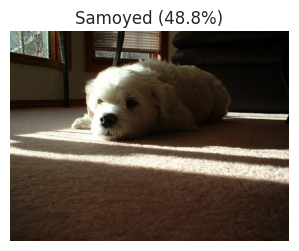

  Samoyed                48.79%
  Old English sheepdog   15.67%
  Golden retriever       11.26%

Real: Rhodesian ridgeback | archivo: n02087394_1250.JPEG


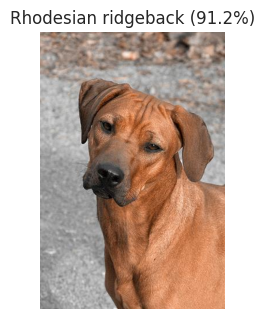

  Rhodesian ridgeback    91.25%
  Border terrier          2.08%
  Golden retriever        1.94%

Real: Beagle | archivo: n02088364_2502.JPEG


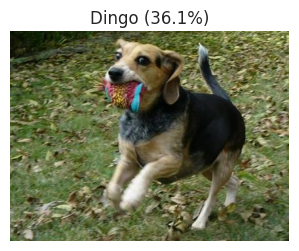

  Dingo                  36.13%
  Beagle                 18.96%
  Border terrier         16.38%

Real: English foxhound | archivo: n02089973_5641.JPEG


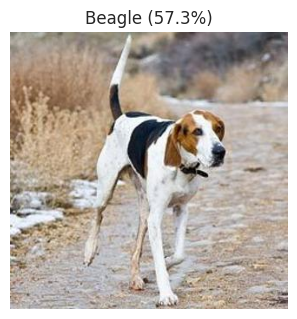

  Beagle                 57.29%
  English foxhound       22.45%
  Dingo                   3.74%

Real: Border terrier | archivo: n02093754_1132.JPEG


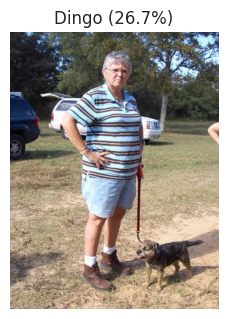

  Dingo                  26.66%
  Beagle                 16.64%
  Samoyed                14.76%

Real: Australian terrier | archivo: n02096294_11091.JPEG


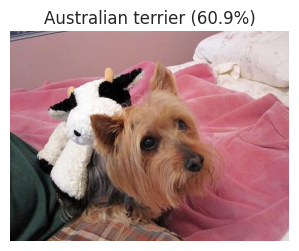

  Australian terrier     60.90%
  Shih-Tzu               13.91%
  Border terrier          7.96%

Real: Golden retriever | archivo: n02099601_521.JPEG


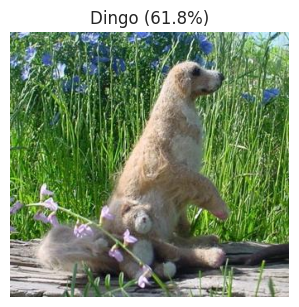

  Dingo                  61.79%
  Border terrier          6.74%
  Beagle                  5.84%

Real: Old English sheepdog | archivo: n02105641_11190.JPEG


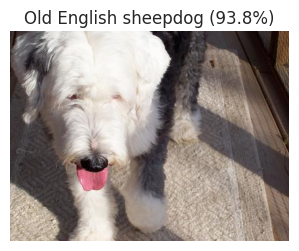

  Old English sheepdog   93.84%
  Shih-Tzu                2.10%
  Samoyed                 1.57%

Real: Samoyed | archivo: n02111889_1841.JPEG


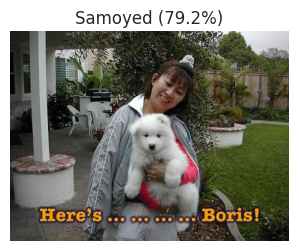

  Samoyed                79.20%
  Old English sheepdog    6.20%
  Beagle                  3.54%

Real: Dingo | archivo: n02115641_5522.JPEG


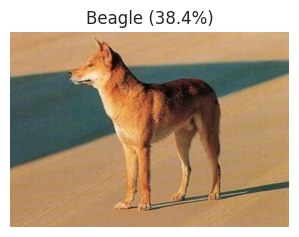

  Beagle                 38.44%
  Dingo                  30.61%
  Border terrier          9.46%


In [20]:
# Prueba con una imagen aleatoria de cada raza del conjunto de prueba
rng = random.Random(7)
for code_ in class_names:
    path = rng.choice(sorted((TEST_DIR / code_).iterdir()))
    print(f"\nReal: {CODE_TO_NAME[code_]} | archivo: {path.name}")
    predict_image(path)